# From one 625 nm photon to parity flips

Every LED pulse deposits the full energy of one 625 nm photon in the substrate. What changes when each LED pulse gets its own expected number of flips? Follow one channel from the initial absorber population to the trapped population, the expected flips $\Lambda_{\rm ch}$, and the realized count $S$. Then compare $S$ with the QPD paper’s complete-pulse model at the same average yield.

All counts below are **simulated LED-induced truth for complete pulses**. Quiescent flips and reconstruction efficiency belong to the readout study. The example uses illustrative Al absorber and Hf trap parameters from the [QPD model, Eqs. 3, 14, 17 and B1](https://doi.org/10.1103/kqd2-spb1).

## Choose a channel

Edit the parameters below and run all cells. The collection fraction includes this channel's share of the energy and absorber pair breaking. To explore a specific geometry, replace 0.20 with the value of `diffusion_trapping_probability(absorber_length_um, trap_length_um)`.

For the symmetric channel, the mobile quasiparticles are shared equally between two 500 µm³ Hf traps. Their combined population is divided by 1,000 µm³ in the tunneling-rate calculation.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
from scipy.constants import c, electron_volt, h
from scipy.stats import exponnorm

# Prefer the source tree containing this notebook over an installed package.
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/qpd").is_dir())
sys.path.insert(0, str(root / "src"))
from qpd import LEDEnergyModel, LEDPulseModel, diffusion_trapping_probability

wavelength_nm = 625.0
photon_energy_ev = h * c / (wavelength_nm * 1e-9 * electron_volt)
print(f"Substrate energy per pulse: {photon_energy_ev:.6f} eV")

model = LEDEnergyModel(
    deposited_energy_ev=photon_energy_ev,
    eta_ce=0.10,
    absorber_gap_ev=190e-6,
    fano_factor=0.20,
    trapping_probability=0.20,
    multiplication_gain=0.5 * 190 / 40,
    tunneling_constant_um3_s=20_000,
    qp_lifetime_s=0.001,
    trap_volume_um3=2 * 500,
)
n_pulses = 40_000
seed = 20261127

ink, teal, gold = "#25364A", "#007F78", "#C57822"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.labelcolor": ink, "text.color": ink, "font.size": 10,
                     "figure.dpi": 120, "axes.titlelocation": "left"})

spec = json.loads((root / "configs/siderius/led_standalone_snr2.json").read_text())
nominal = spec["parameters"]
led = LEDPulseModel(
    energy_model=model,
    mu=spec["burst_mu_s"],
    sigma=nominal["burst_sigma_s"]["nominal"],
    tau=nominal["burst_tau_s"]["nominal"],
    on_time=nominal["on_time_s"]["nominal"],
    off_time=nominal["off_time_s"]["nominal"],
)
print(f"Nominal EMG (ms): μ={1e3*led.mu:g}, σ={1e3*led.sigma:g}, τ={1e3*led.tau:g}")

Substrate energy per pulse: 1.983747 eV
Nominal EMG (ms): μ=0.2, σ=0.4, τ=0.8


## How the population becomes a count

The absorber mean is $\mu=E_{\rm dep}\eta_{\rm CE,ch}/\Delta_{\rm abs}$. The integer sampler targets variance $F\mu$, subject to the minimum feasible variance at that mean. Each absorber quasiparticle has capture probability $p$. Each capture contributes a fixed effective mobile yield $g$, giving $M=gN_{\rm cap}$ and $\Lambda_{\rm ch}=aM$ with $a=K\tau_{\rm qp}/V_{\rm tr}$. The LED simulator then draws $S\mid\Lambda_{\rm ch}\sim\mathrm{Poisson}(\Lambda_{\rm ch})$ and assigns flip times.

In [2]:
def simulate_pulses(led, count, run_seed):
    # End halfway between rising edges to include exactly count complete-pulse truths.
    duration = led.first_pulse_time + (count - 0.5) * led.period
    truth = led.sample(duration, np.random.default_rng(run_seed))
    assert len(truth.bursts) == count
    flips = np.array([burst.n_qp for burst in truth.bursts])
    return truth, flips

truth, flips = simulate_pulses(led, n_pulses, seed)
pop = truth.population
a = model.tunneling_constant_um3_s * model.qp_lifetime_s / model.trap_volume_um3
b = a * model.multiplication_gain  # integrated mean flips per captured quasiparticle
p = model.trapping_probability
mu = model.deposited_energy_ev * model.eta_ce / model.absorber_gap_ev
frac = mu % 1
v_abs = max(model.fano_factor * mu, frac * (1 - frac))
mean_flips = b * p * mu
variance_terms = np.array([mean_flips, b**2 * p * (1 - p) * mu, (b * p)**2 * v_abs])

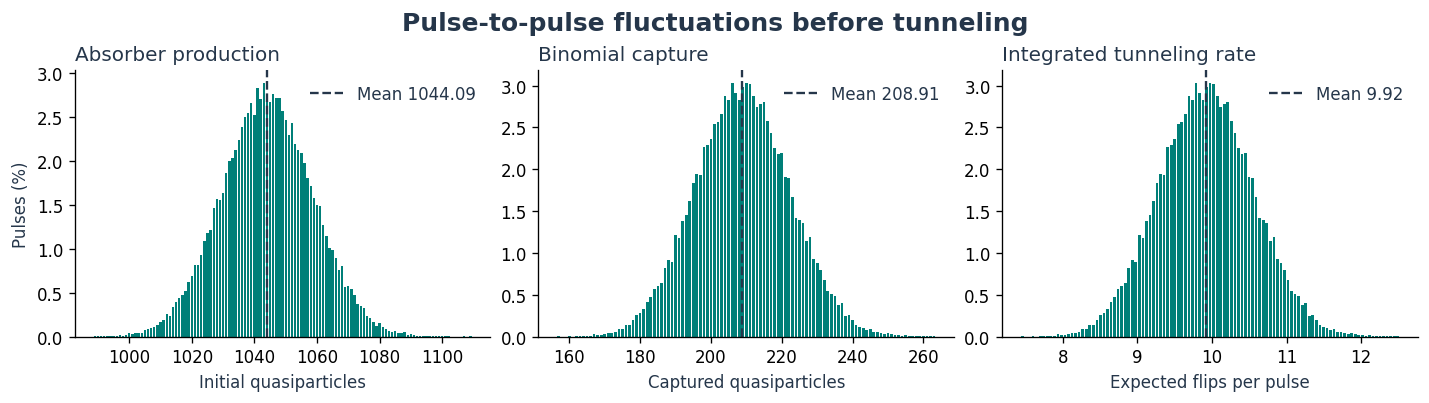

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(11.8, 3.25), layout="constrained")
for ax, values, title, xlabel, step in zip(
    axes, [pop.absorber_qp, pop.captured_qp, pop.lambda_ch],
    ["Absorber production", "Binomial capture", "Integrated tunneling rate"],
    ["Initial quasiparticles", "Captured quasiparticles", "Expected flips per pulse"],
    [1, 1, b or 1],
):
    x, counts = np.unique(values, return_counts=True)
    ax.bar(x, counts / n_pulses * 100, width=step * 0.76, color=teal)
    ax.axvline(values.mean(), color=ink, ls="--", lw=1.4, label=f"Mean {values.mean():.2f}")
    ax.set(title=title, xlabel=xlabel)
    ax.legend(frameon=False)
axes[0].set_ylabel("Pulses (%)")
fig.suptitle("Pulse-to-pulse fluctuations before tunneling", fontsize=15, fontweight="bold")
plt.show()

## Where does the Fano fluctuation enter?

Both models start with the same deposit, efficiencies, fixed trap gain, volume and tunneling constant. Both predict a mean mobile yield $\bar M=g p\mu$ and use $S\mid\Lambda_{\rm ch}\sim\mathrm{Poisson}(\Lambda_{\rm ch})$ for the final LED flips. They differ in the step that generates the spread in $\Lambda_{\rm ch}$.

* **Energy model:** the initial absorber count fluctuates with $F$. Capture adds a binomial draw, then the trap multiplies the captured yield by a fixed gain. The resulting variance of $\Lambda_{\rm ch}$ is $b^2[p(1-p)\mu+p^2\operatorname{Var}(N_{\rm abs})]$, where $b=ag$.
* **Paper model:** mean efficiencies and multiplication set $\bar M$. [Equation (17)](https://doi.org/10.1103/kqd2-spb1) draws the resulting mobile population as $N_F\sim\mathcal N(\bar M,F\bar M)$ (second parameter is variance), then uses $\Lambda_{\rm ch}=aN_F$. Its variance is $a^2 F\bar M$.

For both models, the total flip variance is the sum of the common tunneling shot noise $\mathbb E[S]$ and the respective variance of $\Lambda_{\rm ch}$, as in Eq. (18). The comparison uses our channel parameters and the paper’s count law. The paper’s Gaussian population approximation is appropriate here because the mean is many standard deviations above zero.

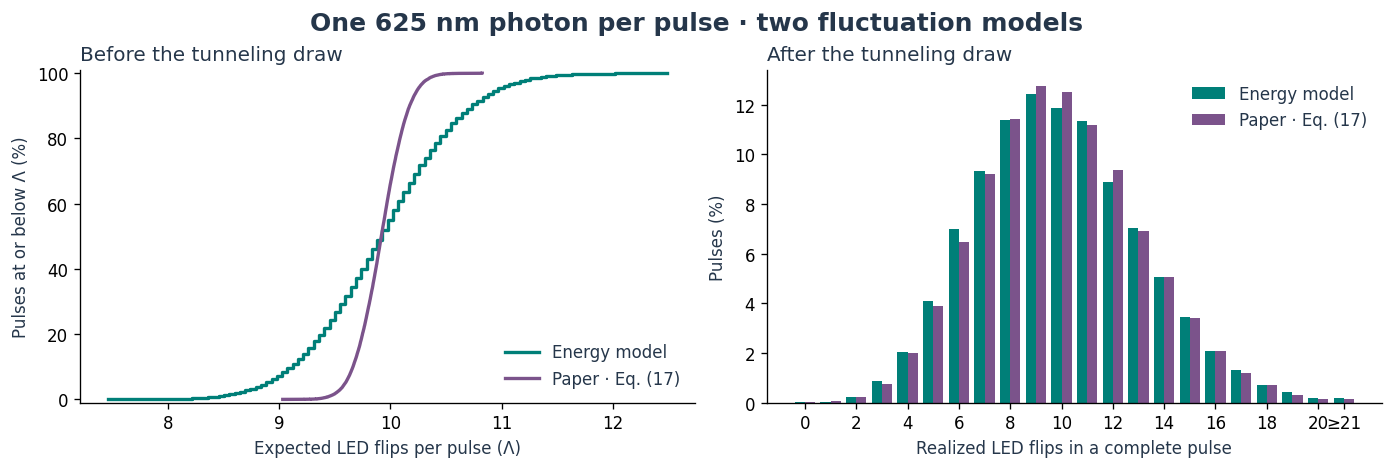

40,000 pulses per model     Energy model             Paper Eq. (17)
                        Sampled    Theory     Sampled    Theory
Mean flips               9.9117    9.9187      9.9220    9.9187
Variance of Λ            0.4027    0.3958      0.0396    0.0397
Flip-count variance     10.3278   10.3145      9.9165    9.9584
Energy-model variance from capture: 0.3769; from absorber production: 0.0188


In [4]:
# Draw independent pulses using the two stochastic steps of Eq. (17).
mean_mobile = model.multiplication_gain * p * mu
paper_mobile_sd = np.sqrt(model.fano_factor * mean_mobile)
paper_rng = np.random.default_rng(np.random.SeedSequence([seed, 17]))
paper_mobile = paper_rng.normal(mean_mobile, paper_mobile_sd, n_pulses)
if np.any(paper_mobile < 0):
    raise ValueError("Eq. (17) produced a negative population at this setting. "
                     "Its Gaussian approximation needs a larger mobile yield.")
paper_lambda = a * paper_mobile
paper_flips = paper_rng.poisson(paper_lambda)

energy_lambda_var = variance_terms[1:].sum()
paper_lambda_var = a**2 * model.fano_factor * mean_mobile
fig, (rates, counts_ax) = plt.subplots(1, 2, figsize=(11.5, 3.8), layout="constrained")
colors = [teal, "#7B538B"]
labels = ["Energy model", "Paper · Eq. (17)"]

# Empirical CDF includes all pulses and preserves the energy model’s discrete rate levels.
for values, color, label in zip([pop.lambda_ch, paper_lambda], colors, labels):
    levels, frequency = np.unique(values, return_counts=True)
    rates.step(levels, 100 * frequency.cumsum() / n_pulses, where="post",
               color=color, label=label, lw=2)
rates.set(title="Before the tunneling draw", xlabel="Expected LED flips per pulse (Λ)",
          ylabel="Pulses at or below Λ (%)", ylim=(-1, 101))
rates.legend(frameon=False, loc="lower right")

# Pool the far upper tail in a labeled bin; both histograms have unit total mass.
last = max(2, int(np.ceil(np.quantile(np.r_[flips, paper_flips], 0.999))))
k = np.arange(last + 1)
for values, offset, color, label in zip([flips, paper_flips], [-0.2, 0.2], colors, labels):
    frequency = np.bincount(np.minimum(values, last), minlength=last + 1)
    counts_ax.bar(k + offset, 100 * frequency / n_pulses, 0.4, color=color, label=label)
ticks = np.unique(np.r_[np.arange(0, last, max(1, last // 8)), last])
counts_ax.set_xticks(ticks, [str(i) if i < last else f"≥{last}" for i in ticks])
counts_ax.set(title="After the tunneling draw", xlabel="Realized LED flips in a complete pulse",
              ylabel="Pulses (%)")
counts_ax.legend(frameon=False)
fig.suptitle(f"One {wavelength_nm:g} nm photon per pulse · two fluctuation models",
             fontsize=15, fontweight="bold")
plt.show()

print(f"{n_pulses:,} pulses per model     Energy model             Paper Eq. (17)")
print(f"{'':22}{'Sampled':>9} {'Theory':>9}   {'Sampled':>9} {'Theory':>9}")
for quantity, energy_obs, energy_ref, paper_obs, paper_ref in [
    ("Mean flips", flips.mean(), mean_flips, paper_flips.mean(), a * mean_mobile),
    ("Variance of Λ", pop.lambda_ch.var(), energy_lambda_var, paper_lambda.var(), paper_lambda_var),
    ("Flip-count variance", flips.var(), mean_flips + energy_lambda_var,
     paper_flips.var(), mean_flips + paper_lambda_var),
]:
    print(f"{quantity:<22}{energy_obs:9.4f} {energy_ref:9.4f}   {paper_obs:9.4f} {paper_ref:9.4f}")
print(f"Energy-model variance from capture: {variance_terms[1]:.4f}; "
      f"from absorber production: {variance_terms[2]:.4f}")

## Where do the flips land in time?

The [nominal pipeline template](../configs/siderius/led_standalone_snr2.json) is an exponentially modified Gaussian (EMG) with Gaussian location 0.2 ms, width 0.4 ms, and exponential decay 0.8 ms. The simulator resamples negative delays. Its 50 µs excitation window adds a mean offset of only 25 µs.

The histogram sums all LED-induced flips relative to their own rising edges and divides by the number of pulses and bin width. The template curve has area equal to the predicted mean flips per pulse.

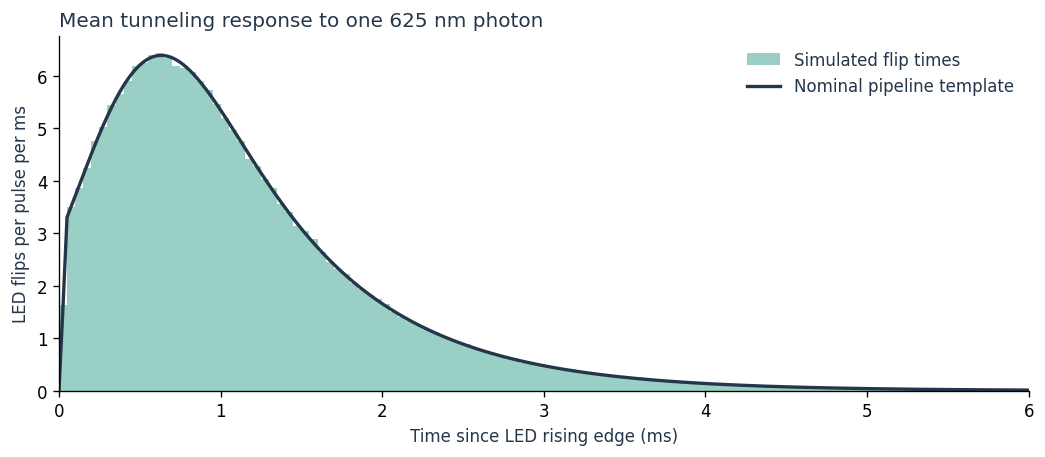

Flips within 3 ms: 96.21%  |  Template peak: 0.630 ms


In [5]:
delay_ms = 1e3 * np.concatenate([burst.event_times - burst.t_arrival for burst in truth.bursts])
edges = np.linspace(0, 6, 121)
counts, _ = np.histogram(delay_ms, bins=edges)

# For a uniform excitation time, the delay density is the difference of
# two causal EMG CDF values divided by the excitation width.
emg = exponnorm(led.tau / led.sigma, loc=1e3 * led.mu, scale=1e3 * led.sigma)
width_ms = 1e3 * led.on_time
t = np.linspace(0, edges[-1], 1201)
def causal_cdf(x):
    return (emg.cdf(np.maximum(x, 0)) - emg.cdf(0)) / emg.sf(0)

density = (causal_cdf(t) - causal_cdf(t - width_ms)) / width_ms
fig, ax = plt.subplots(figsize=(8.6, 3.7), layout="constrained")
ax.stairs(counts / (n_pulses * np.diff(edges)), edges, fill=True, color="#9ACFC5",
          label="Simulated flip times")
ax.plot(t, mean_flips * density, color=ink, lw=2, label="Nominal pipeline template")
ax.set(xlabel="Time since LED rising edge (ms)", ylabel="LED flips per pulse per ms",
       title=f"Mean tunneling response to one {wavelength_nm:g} nm photon", xlim=(0, edges[-1]), ylim=(0, None))
ax.legend(frameon=False)
plt.show()
if delay_ms.size:
    print(f"Flips within 3 ms: {np.mean(delay_ms < 3):.2%}  |  Template peak: {t[density.argmax()]:.3f} ms")

The first 30 consecutive pulses show how individual realizations sample the same timing template. Each dot marks one flip.

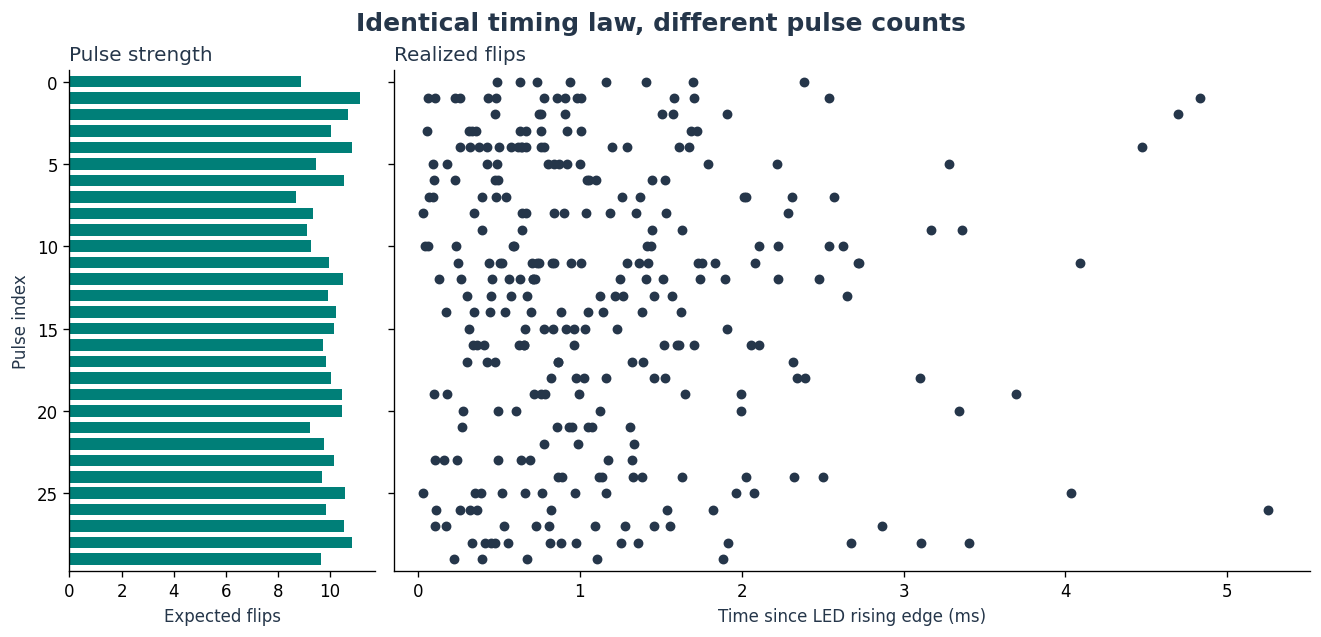

In [6]:
rows = min(30, n_pulses)
fig, (strength, raster) = plt.subplots(1, 2, figsize=(10.9, 5.2), sharey=True,
                                       gridspec_kw={"width_ratios": [1, 3]}, layout="constrained")
pulse_index = np.arange(rows)
strength.barh(pulse_index, pop.lambda_ch[:rows], height=0.70, color=teal)
strength.set(xlabel="Expected flips", ylabel="Pulse index", title="Pulse strength")
for i, burst in enumerate(truth.bursts[:rows]):
    delay_ms = 1e3 * (burst.event_times - burst.t_arrival)
    raster.scatter(delay_ms, np.full(delay_ms.size, i), s=24, color=ink)
raster.set(xlabel="Time since LED rising edge (ms)", title="Realized flips")
strength.set_ylim(rows - 0.3, -0.7)
raster.set_xlim(left=-0.15)
fig.suptitle("Identical timing law, different pulse counts", fontsize=15, fontweight="bold")
plt.show()

Most variance comes from counting individual crossings. To explore when capture fluctuations become more visible, increase the tunneling constant and rerun. The shot-noise term grows linearly in crossings per capture, while the two population terms grow quadratically.